In [1]:
import requests
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from datetime import date, timedelta

In [2]:
def get_da_prices(day):
    """Download one day of IESO Day-Ahead hourly Ontario Zonal Prices."""
    url = ("https://reports-public.ieso.ca/public/DAHourlyOntarioZonalPrice/"
           f"PUB_DAHourlyOntarioZonalPrice_{day:%Y%m%d}.xml")
    response = requests.get(url, timeout=30)
    if response.status_code != 200:
        print("No file for", day)
        return []

    root = ET.fromstring(response.content)
    ns = {"ieso": "http://www.ieso.ca/schema"}   # IESO's XML namespace
    rows = []
    for hour in root.findall(".//ieso:HourlyPriceComponents", ns):
        rows.append({
            "date": str(day),
            "hour": int(hour.find("ieso:PricingHour", ns).text),
            "price": float(hour.find("ieso:ZonalPrice", ns).text),
        })
    return rows


all_rows = []
for days_ago in range(14, 0, -1):          # 14 days ago ... yesterday
    day = date.today() - timedelta(days=days_ago)
    all_rows += get_da_prices(day)

prices = pd.DataFrame(all_rows)
print(len(prices), "hourly prices downloaded")
prices.head()

336 hourly prices downloaded


,date,hour,price
0,2026-10-05,1,24.68
1,2026-10-05,2,25.14
2,2026-10-05,3,25.42
3,2026-10-05,4,28.44
4,2026-10-05,5,32.72


In [3]:
demand_url = f"https://reports-public.ieso.ca/public/Demand/PUB_Demand_{date.today().year}.csv"
demand = pd.read_csv(demand_url, skiprows=3)
demand.columns = ["date", "hour", "market_demand_mw", "ontario_demand_mw"]

print(len(demand), "hourly demand rows")
demand.tail()

6985 hourly demand rows


,date,hour,market_demand_mw,ontario_demand_mw
6980,2026-10-18,21,18254,14794
6981,2026-10-18,22,17733,14238
6982,2026-10-18,23,17476,13751
6983,2026-10-18,24,17010,13274
6984,2026-10-19,1,16538,12836


In [4]:
conn = sqlite3.connect("ieso.db")
prices.to_sql("da_prices", conn, if_exists="replace", index=False)
demand.to_sql("demand", conn, if_exists="replace", index=False)

def sql(query):
    """Run a SQL query against ieso.db and return the result as a table."""
    return pd.read_sql(query, conn)

sql("SELECT name AS table_name FROM sqlite_master WHERE type = 'table'")

,table_name
0,da_prices
1,demand


In [5]:
daily_summary = sql("""
SELECT date,
       ROUND(AVG(price), 2) AS avg_price,
       MIN(price)           AS min_price,
       MAX(price)           AS max_price
FROM da_prices
GROUP BY date
ORDER BY date
""")
daily_summary

,date,avg_price,min_price,max_price
0,2026-10-05,44.87,24.68,105.93
1,2026-10-06,50.64,32.23,104.34
2,2026-10-07,49.88,22.27,98.65
3,2026-10-08,45.38,29.75,93.55
4,2026-10-09,54.00,36.67,103.17
5,2026-10-10,42.83,35.03,64.00
6,2026-10-11,50.58,32.96,80.54
7,2026-10-12,49.48,35.49,73.16
8,2026-10-13,64.39,33.71,104.07
9,2026-10-14,65.11,41.94,100.28


In [6]:
top_hours = sql("""
SELECT date, hour, price
FROM da_prices
ORDER BY price DESC
LIMIT 10
""")
top_hours

,date,hour,price
0,2026-10-05,19,105.93
1,2026-10-06,7,104.34
2,2026-10-13,17,104.07
3,2026-10-09,19,103.17
4,2026-10-13,18,102.22
5,2026-10-06,19,101.39
6,2026-10-13,19,101.22
7,2026-10-14,18,100.28
8,2026-10-14,19,100.04
9,2026-10-07,19,98.65


In [7]:
by_hour = sql("""
SELECT hour,
       ROUND(AVG(price), 2) AS avg_price
FROM da_prices
GROUP BY hour
ORDER BY hour
""")
by_hour

,hour,avg_price
0,1,35.64
1,2,37.18
2,3,36.23
3,4,35.43
4,5,38.41
5,6,48.06
6,7,61.81
7,8,55.85
8,9,48.95
9,10,49.45


In [8]:
daily_cost = sql("""
SELECT p.date,
       SUM(d.ontario_demand_mw)                                          AS total_demand_mwh,
       ROUND(AVG(p.price), 2)                                            AS avg_price,
       ROUND(SUM(d.ontario_demand_mw * p.price) / SUM(d.ontario_demand_mw), 2) AS demand_weighted_price,
       ROUND(SUM(d.ontario_demand_mw * p.price) / 1000000.0, 2)         AS est_energy_cost_millions
FROM da_prices p
JOIN demand d
  ON d.date = p.date
 AND d.hour = p.hour
GROUP BY p.date
ORDER BY p.date
""")
daily_cost

,date,total_demand_mwh,avg_price,demand_weighted_price,est_energy_cost_millions
0,2026-10-05,359665,44.87,46.16,16.60
1,2026-10-06,366232,50.64,51.76,18.95
2,2026-10-07,369545,49.88,51.35,18.97
3,2026-10-08,367367,45.38,46.27,17.00
4,2026-10-09,367732,54.00,54.79,20.15
5,2026-10-10,347248,42.83,43.08,14.96
6,2026-10-11,347603,50.58,51.45,17.89
7,2026-10-12,348351,49.48,50.11,17.46
8,2026-10-13,393337,64.39,66.78,26.27
9,2026-10-14,380838,65.11,66.24,25.23


In [9]:
quality_check = sql("""
SELECT p.date,
       COUNT(*)                   AS price_hours,
       COUNT(d.ontario_demand_mw) AS hours_with_demand,
       CASE WHEN COUNT(*) = 24 AND COUNT(d.ontario_demand_mw) = 24
            THEN 'OK' ELSE 'CHECK' END AS status
FROM da_prices p
LEFT JOIN demand d
  ON d.date = p.date
 AND d.hour = p.hour
GROUP BY p.date
ORDER BY p.date
""")
quality_check

,date,price_hours,hours_with_demand,status
0,2026-10-05,24,24,OK
1,2026-10-06,24,24,OK
2,2026-10-07,24,24,OK
3,2026-10-08,24,24,OK
4,2026-10-09,24,24,OK
5,2026-10-10,24,24,OK
6,2026-10-11,24,24,OK
7,2026-10-12,24,24,OK
8,2026-10-13,24,24,OK
9,2026-10-14,24,24,OK


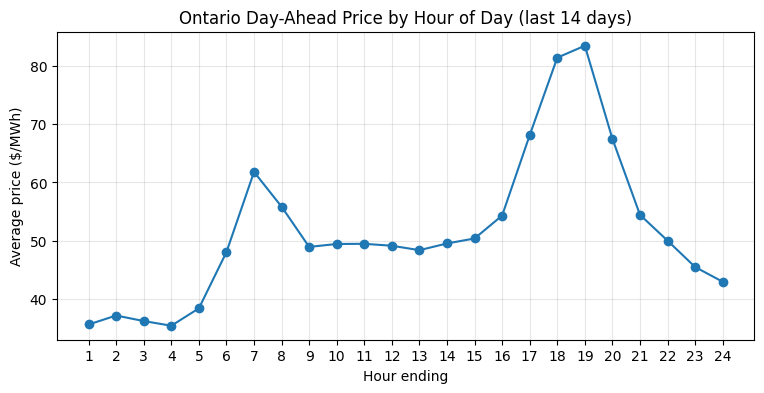

In [10]:
plt.figure(figsize=(9, 4))
plt.plot(by_hour["hour"], by_hour["avg_price"], marker="o")
plt.title("Ontario Day-Ahead Price by Hour of Day (last 14 days)")
plt.xlabel("Hour ending")
plt.ylabel("Average price ($/MWh)")
plt.xticks(range(1, 25))
plt.grid(alpha=0.3)
plt.show()

In [11]:
with pd.ExcelWriter("ieso_market_report.xlsx") as writer:
    daily_summary.to_excel(writer, sheet_name="Daily Summary", index=False)
    top_hours.to_excel(writer, sheet_name="Top 10 Hours", index=False)
    by_hour.to_excel(writer, sheet_name="Price by Hour", index=False)
    daily_cost.to_excel(writer, sheet_name="Demand and Cost", index=False)
    quality_check.to_excel(writer, sheet_name="Data Quality", index=False)

print("Saved ieso_market_report.xlsx")

try:
    from google.colab import files   # only works inside Colab
    files.download("ieso_market_report.xlsx")
except ImportError:
    pass

Saved ieso_market_report.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>